# Exercice 4 : Détecter sans règle : anomalies et faux positifs

> **En une phrase :** au lieu de décrire l'attaque, on décrit **le normal** et on signale tout ce qui s'en écarte. Ça attrape des attaques inconnues… et ça produit des **faux positifs** en masse. On mesure pourquoi.

**Le scénario.** Les règles des exercices 2 et 3 ne voient que ce qu'on connaît déjà. Votre responsable veut essayer la « détection d'anomalies » qu'on lui a vendue. Vous la testez sur le journal SSH.

**La source.** Le journal SSH de l'exercice 1 (*Loghub*).

**Le plan.**
1. Une anomalie dans le temps : un pic d'activité.
2. Une anomalie de comportement : les IP « bizarres » (apprentissage automatique).
3. Le piège du **taux de base** : pourquoi 99 % des alertes sont fausses.

## Étape 0 : exécutez cette cellule en premier
Le notebook est **autonome** : il fonctionne tel quel sur Colab (ouvert depuis Drive) ou en local. Elle doit afficher **Prêt**.

In [1]:
import re, requests
import pandas as pd

URL_SSH = "https://raw.githubusercontent.com/logpai/loghub/master/OpenSSH/OpenSSH_2k.log"

def charger_ssh():
    """Télécharge le journal SSH et le range dans un tableau : une ligne = un événement."""
    lignes = requests.get(URL_SSH, timeout=30).text.splitlines()
    motif = re.compile(r"^(\w{3}\s+\d+ \d\d:\d\d:\d\d) \S+ sshd\[\d+\]: (.*)$")
    evenements = []
    for ligne in lignes:
        m = motif.match(ligne)
        if m:
            ip = re.search(r"\d+\.\d+\.\d+\.\d+", m.group(2))
            evenements.append({"heure": pd.to_datetime("2016 " + m.group(1), format="%Y %b %d %H:%M:%S"),  # l'année n'est pas écrite dans le journal
                               "message": m.group(2),
                               "ip": ip.group() if ip else None})
    return pd.DataFrame(evenements), lignes

import numpy as np
from sklearn.ensemble import IsolationForest

evenements, _ = charger_ssh()
print('Prêt')

Prêt


## Étape 1 : Un pic d'activité
**Ce qu'on fait :** on compte **tous** les événements par minute, sans regarder ce qu'ils disent. Le « normal », c'est la valeur habituelle (la **médiane**). On signale toute minute **au-dessus de 5 fois** l'écart habituel.

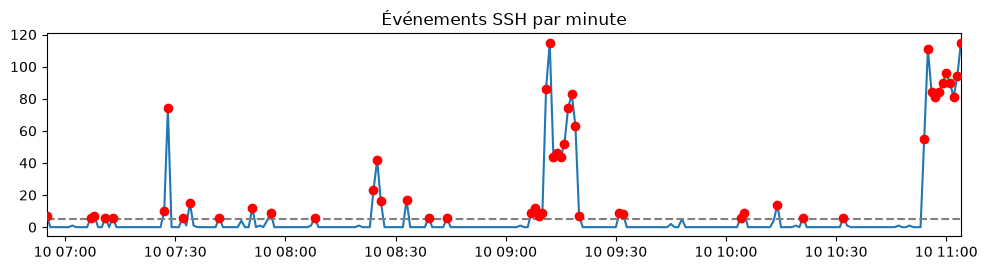

In [16]:
import matplotlib.pyplot as plt

# Tracé direct avec Matplotlib pour éviter le bug de conversion de Pandas
fig, ax = plt.subplots(figsize=(10, 2.8))

ax.plot(par_minute.index, par_minute.values, label="Événements")
ax.scatter(anomalies.index, anomalies.values, color="red", zorder=3, label="Anomalies")
ax.axhline(seuil, color="grey", linestyle="--")

ax.set_title("Événements SSH par minute")
ax.set_xlim(par_minute.index.min(), par_minute.index.max())

plt.tight_layout()
plt.show()

**👀 Ce qu'on doit voir :** la même forme que le schéma du cours (*Anomaly* sur une courbe). Une minute normale compte **0** événement ; le seuil est à **5**. **51 minutes sur 250** sont signalées, et les points rouges tombent sur les rafales de l'exercice 1 (vers 09:10-09:20 et 10:54-11:04).

In [3]:
# Qui est derrière les minutes anormales ?
minutes = set(anomalies.index)
dans_anomalies = evenements[evenements["heure"].dt.floor("1min").isin(minutes)]
dans_anomalies["ip"].value_counts().head(5)

ip
183.62.140.253     867
187.141.143.180    349
103.99.0.122       172
112.95.230.3        80
5.188.10.180        53
Name: count, dtype: int64

**👀 Ce qu'on doit voir :** les mêmes IP qu'à l'exercice 1 (183.62.140.253, 187.141.143.180…). **Sans savoir** ce que veut dire « Failed password », le détecteur a trouvé les attaques.

## Étape 2 : Les IP au comportement anormal
**Ce qu'on fait :** on décrit chaque IP par quelques chiffres (combien d'événements, combien de comptes différents essayés, quelle part d'échecs, combien de temps elle reste), puis un algorithme d'apprentissage non supervisé, **Isolation Forest**, isole celles qui ne ressemblent pas aux autres. On ne lui dit **jamais** ce qu'est une attaque.

In [4]:
e = evenements.dropna(subset=["ip"]).copy()
e["compte"] = e["message"].str.extract(r"(?:for|user) (?:invalid user )?(\S+) from")[0]
e["echec"] = e["message"].str.startswith("Failed")
e["reussi"] = e["message"].str.startswith("Accepted")

profil = e.groupby("ip").agg(evenements=("message", "size"),
                             comptes_differents=("compte", "nunique"),
                             part_echecs=("echec", "mean"),
                             duree_min=("heure", lambda h: (h.max() - h.min()).total_seconds() / 60),
                             connexion_reussie=("reussi", "any"))

modele = IsolationForest(contamination=0.15, random_state=0)      # <-- MODIFIABLE : % d'IP à signaler
profil["anomalie"] = modele.fit_predict(profil.drop(columns="connexion_reussie")) == -1
print(profil["anomalie"].sum(), "IP signalées sur", len(profil))
profil[profil["anomalie"]].sort_values("evenements", ascending=False).round(2)

5 IP signalées sur 30


,evenements,comptes_differents,part_echecs,duree_min,connexion_reussie,anomalie
ip,,,,,,
183.62.140.253,867,10,0.33,10.27,False,True
187.141.143.180,349,28,0.23,7.28,False,True
103.99.0.122,172,19,0.27,113.42,False,True
52.80.34.196,15,3,0.33,193.52,False,True
202.100.179.208,8,2,0.25,223.47,False,True


**👀 Ce qu'on doit voir :** **5 IP signalées sur 30**. Les trois grosses attaques (183.62.140.253, 187.141.143.180, 103.99.0.122), et surtout **52.80.34.196** : l'attaquant **lent** que la règle à seuil de l'exercice 2 ne voyait jamais. Son anomalie n'est pas le volume, c'est la **durée** (plus de 3 heures). Idem pour 202.100.179.208 (8 événements étalés sur près de 4 heures).

In [5]:
# Et l'utilisateur légitime de l'exercice 1 ?
profil.loc[["119.137.62.142"]].round(2)

,evenements,comptes_differents,part_echecs,duree_min,connexion_reussie,anomalie
ip,,,,,,
119.137.62.142,2,1,0.0,12.77,True,False


**❓ Question pour la classe :** l'utilisateur `fztu` (119.137.62.142) a-t-il été signalé ? Qu'est-ce que ça dit de la méthode ?

*Réponse : **non** (`anomalie = False`) : 2 événements, 1 compte, 0 échec, c'est le profil de la plupart des IP du journal. Pourtant c'est la **seule** IP qui soit vraiment **entrée** sur le serveur. Si c'était un attaquant avec un mot de passe volé, la détection d'anomalies l'aurait laissé passer, car il se comporte « normalement ». Elle signale ce qui est **rare**, pas ce qui est **dangereux** : un attaquant discret passe, et un administrateur qui travaille tard est signalé. Le résultat dépend aussi du réglage : relancez avec `contamination=0.05` puis `0.30`.*

## Étape 3 : Le piège du taux de base
**Ce qu'on fait :** le cours affirme que la grande majorité des alertes reçues par un SOC sont des faux positifs. On le démontre avec une simple multiplication. Imaginons un **excellent** détecteur : il attrape **99 %** des attaques et ne se trompe que sur **1 %** des événements normaux.

In [6]:
evenements_par_jour = 1_000_000      # <-- MODIFIABLE : un SOC de taille moyenne
attaques_par_jour   = 10             # <-- MODIFIABLE : les attaques sont RARES
taux_detection      = 0.99           # le détecteur attrape 99 % des attaques
taux_fausse_alerte  = 0.01           # et se trompe sur 1 % des événements normaux

vrais_positifs = attaques_par_jour * taux_detection
faux_positifs  = (evenements_par_jour - attaques_par_jour) * taux_fausse_alerte
alertes = vrais_positifs + faux_positifs

print(f"Alertes par jour      : {alertes:>9,.0f}".replace(",", " "))
print(f"  dont vraies attaques : {vrais_positifs:>9,.1f}".replace(",", " "))
print(f"  dont fausses alertes : {faux_positifs:>9,.0f}".replace(",", " "))
print(f"\nUne alerte sur {alertes / vrais_positifs:,.0f} est une vraie attaque ({vrais_positifs / alertes:.2%})".replace(",", " "))

Alertes par jour      :    10 010
  dont vraies attaques :       9.9
  dont fausses alertes :    10 000

Une alerte sur 1 011 est une vraie attaque (0.10%)


**👀 Ce qu'on doit voir :** **≈ 10 000 alertes par jour**, dont **≈ 10** vraies. **Une alerte sur 1 000** est une attaque (0,1 %). Le détecteur est excellent ; c'est la **rareté** des attaques qui crée les faux positifs.

In [7]:
# Que faut-il améliorer pour que la moitié des alertes soient vraies ?
for fa in [0.01, 0.001, 0.0001, 0.00001]:
    fp = (evenements_par_jour - attaques_par_jour) * fa
    print(f"fausse alerte {fa:>8.3%} → {vrais_positifs + fp:>8,.0f} alertes/jour, {vrais_positifs / (vrais_positifs + fp):>6.1%} de vraies".replace(",", " "))

fausse alerte   1.000% →   10 010 alertes/jour    0.1% de vraies
fausse alerte   0.100% →    1 010 alertes/jour    1.0% de vraies
fausse alerte   0.010% →      110 alertes/jour    9.0% de vraies
fausse alerte   0.001% →       20 alertes/jour   49.7% de vraies


**👀 Ce qu'on doit voir :** il faut descendre à **0,001 %** de fausses alertes (une sur 100 000 événements) pour qu'environ la moitié des alertes soient vraies. Aucun détecteur réel n'y arrive seul.

**❓ Question pour la classe :** si on ne peut pas réduire assez les fausses alertes du détecteur, que peut faire le SOC ?

*Réponse : ne pas montrer chaque alerte à un humain. On **regroupe** les alertes qui parlent de la même chose (corrélation), on **enrichit** avec du contexte (renseignement, criticité de la machine) et on **trie** par priorité. C'est exactement le rôle du SIEM : exercice 5.*

## Ce qu'il faut retenir
- La détection d'**anomalies** n'a besoin d'aucun IoC : elle a trouvé les attaques sans savoir ce qu'est « Failed password ». Elle peut donc voir des attaques **inconnues**.
- Mais elle signale ce qui est **rare**, pas ce qui est **dangereux** : l'utilisateur légitime peut devenir l'anomalie.
- **Le piège du taux de base** : quand les attaques sont rares, même un détecteur à 99 % produit une écrasante majorité de faux positifs. D'où la fatigue des analystes SOC.
- Les attaquants le savent : ils restent **lents et discrets** pour se fondre dans le « normal », ce qui explique en partie pourquoi on met souvent des semaines, voire des mois, à découvrir une intrusion.

**Exercice suivant :** transformer des centaines d'alertes en une poignée d'incidents.